查看win/lose

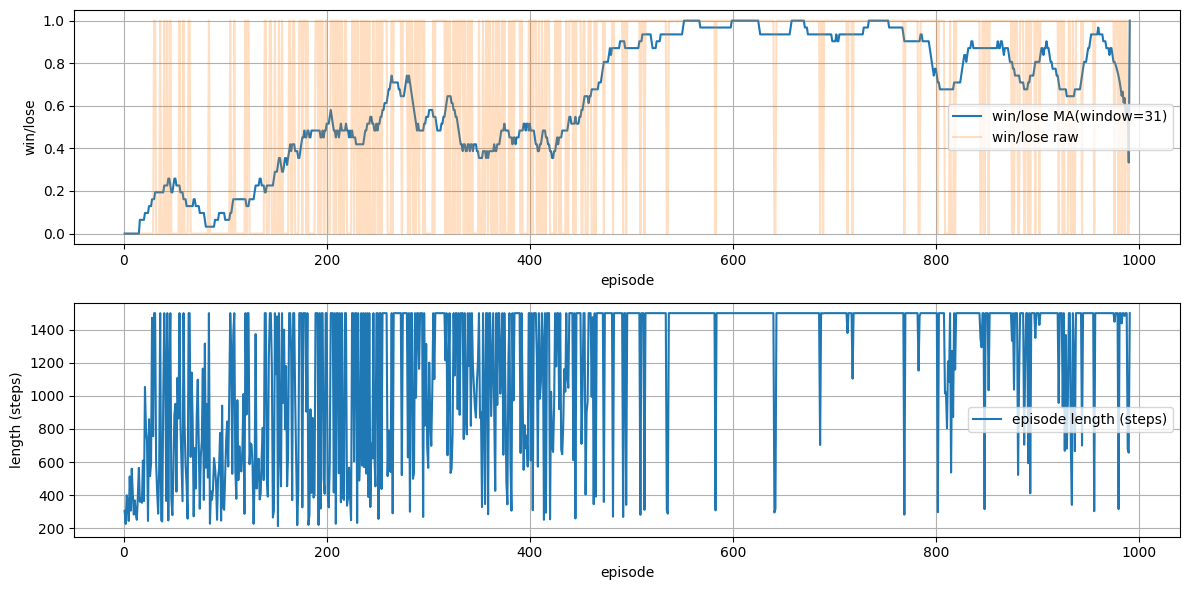

In [1]:
# 在一个新的 code cell 中粘贴并运行下面代码（若 CSV 不在当前工作目录，请把 file_path 改为文件的完整路径）

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = "Escape-run-20251015-225735.csv"  # 若需要，改为完整路径

# 读取 csv（第1列 walltime, 第2列 steps, 第3列 win/lose）
df = pd.read_csv(file_path, header=0)  # 如果没有表头，可使用 header=None

# 取出 columns：第二列为 steps，第三列为 win/lose（按你的描述）
steps = df.iloc[:, 1].to_numpy(dtype=np.float64)
winlose = df.iloc[:, 2].to_numpy(dtype=np.float64)

# episodes 从 1 开始，与 winlose 长度一致
episodes = np.arange(1, len(winlose) + 1)

# moving_average 函数（与你 notebook 中的实现保持一致）
def moving_average(a, window_size):
    a = np.asarray(a, dtype=np.float64)
    if window_size <= 1:
        return a.copy()
    cumulative_sum = np.cumsum(np.insert(a, 0, 0.0))
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    if window_size - 1 > 0:
        r = np.arange(1, window_size - 1, 2)
        begin = np.cumsum(a[:window_size - 1])[::2] / r
        end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
        return np.concatenate((begin, middle, end))
    else:
        return middle

# 1) episodes - win/lose 曲线（滑动平均）
winlose_ma = moving_average(winlose, 31)

# 2) episodes - 回合长度曲线（steps 差分，第一项为 steps[0]）
episode_lengths = np.empty_like(steps)
if steps.size > 0:
    episode_lengths[0] = steps[0]
    if steps.size > 1:
        episode_lengths[1:] = steps[1:] - steps[:-1]

# 绘图
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(episodes, winlose_ma, label=f'win/lose MA(window=31)')
plt.plot(episodes, winlose, alpha=0.25, label='win/lose raw')
plt.xlabel('episode')
plt.ylabel('win/lose')
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(episodes, episode_lengths, label='episode length (steps)')
plt.xlabel('episode')
plt.ylabel('length (steps)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()